# 05 - Algorithmic Trading Simulation & Backtesting
## Machine Learning Lab Project: Cryptocurrency Price Forecasting

### 🎯 Objective
Execute a rigorous financial simulation using our trained machine learning models:
- **Initial Capital:** Exactly **$10,000.00** USD starting cash balance.
- **Fee Model:** **0.1% transaction fee** (standard exchange taker rate).
- **Execution Strategy:** Long / Cash regime driven by model expected returns.
- **Granular Trade Log:** Record timestamp, entry price, exit price, position size, fees paid, individual PnL, and running balance for every single trade.
- **Risk Metrics:** Final Balance, Net Return %, Win Rate %, Max Drawdown %, and Sharpe Ratio compared against the Bitcoin Buy & Hold benchmark.

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath('..'))
import src

os.makedirs('../results', exist_ok=True)
print("Initialized Backtesting Engine with initial capital = $10,000.00")

Initialized Backtesting Engine with initial capital = $10,000.00


### 🧪 Backtest 1: Detailed Trade Log on Primary 1h Timeframe

In [2]:
# Load 1h dataset and train LightGBM
df_1h = pd.read_csv('../data/processed/BTC_USDT_1h_features.csv')
df_1h['timestamp'] = pd.to_datetime(df_1h['timestamp'])
split_1h = src.temporal_train_test_split(df_1h, src.FEATURE_COLUMNS)
models_1h = src.train_and_evaluate_models(split_1h)

# Run Backtest with $10,000
backtester = src.Backtester(initial_capital=10000.0, fee_pct=0.001)
summary_1h, trade_log_1h, equity_1h = backtester.run(
    split_1h['test_df'],
    models_1h['LightGBM']['predictions'],
    model_name='LightGBM',
    timeframe='1h'
)

print(f"Total Trades Executed: {len(trade_log_1h)}")
print(f"Final Balance: ${summary_1h['Final_Balance']:.2f} (Return: {summary_1h['Total_Return_%']}%)")
print(f"Win Rate: {summary_1h['Win_Rate_%']}%")
trade_log_1h.head(10)

Total Trades Executed: 11
Final Balance: $9977.56 (Return: -0.22%)
Win Rate: 27.27%


,Trade_ID,Timeframe,Model,Entry_Time,Exit_Time,Entry_Price,Exit_Price,Position_BTC,Trade_PnL_$,Trade_Return_%,Capital_After_Trade
0,1,1h,LightGBM,2026-10-14 13:00:00,2026-10-15 02:00:00,82324.16,81538.01,0.121228,-115.29,-1.15,9884.71
1,2,1h,LightGBM,2026-10-15 03:00:00,2026-10-15 14:00:00,80928.00,81871.95,0.121898,95.30,0.97,9980.01
2,3,1h,LightGBM,2026-10-15 16:00:00,2026-10-15 17:00:00,82108.01,82439.70,0.121304,20.29,0.20,10000.30
3,4,1h,LightGBM,2026-10-15 19:00:00,2026-10-15 21:00:00,82384.73,82425.10,0.121143,-15.10,-0.15,9985.20
4,5,1h,LightGBM,2026-10-16 02:00:00,2026-10-16 03:00:00,82040.86,82126.01,0.121467,-9.62,-0.10,9975.58
5,6,1h,LightGBM,2026-10-16 16:00:00,2026-10-17 15:00:00,81436.11,81355.20,0.122251,-29.83,-0.30,9945.75
6,7,1h,LightGBM,2026-10-17 19:00:00,2026-10-17 22:00:00,81600.00,81355.91,0.121641,-49.58,-0.50,9896.17
7,8,1h,LightGBM,2026-10-18 01:00:00,2026-10-18 13:00:00,81657.38,81540.15,0.120949,-33.96,-0.34,9862.21
8,9,1h,LightGBM,2026-10-18 17:00:00,2026-10-19 02:00:00,81193.87,82718.69,0.121222,165.13,1.68,10027.34
9,10,1h,LightGBM,2026-10-19 15:00:00,2026-10-20 01:00:00,81942.44,81798.15,0.122126,-37.67,-0.38,9989.67


### 📊 Equity Curve Comparison: ML Strategy vs Benchmark Buy & Hold

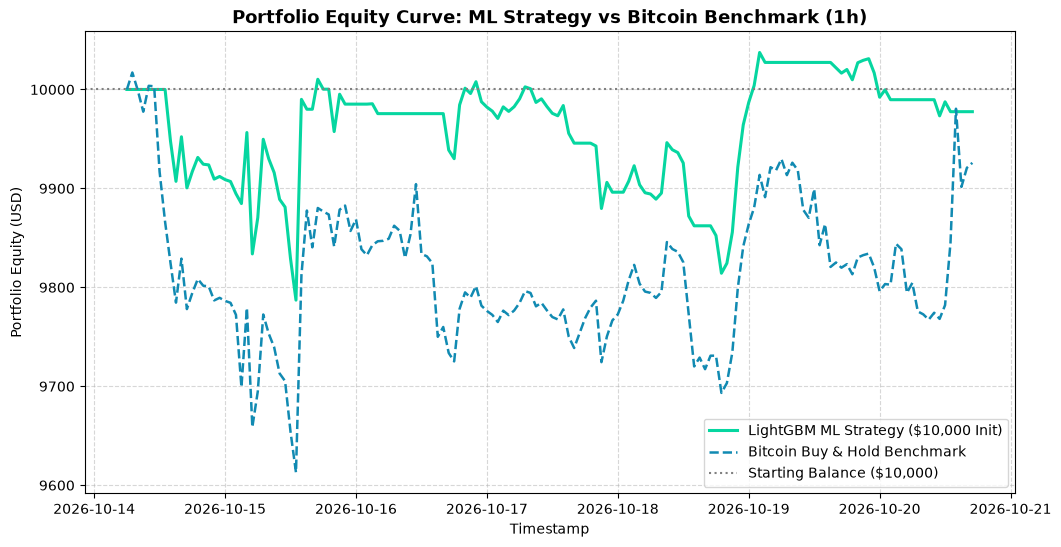

In [3]:
plt.figure(figsize=(12, 6))

initial_price = equity_1h['price'].iloc[0]
benchmark_equity = 10000.0 * (equity_1h['price'] / initial_price)

plt.plot(equity_1h['timestamp'], equity_1h['equity'], label='LightGBM ML Strategy ($10,000 Init)', color='#06d6a0', lw=2.2)
plt.plot(equity_1h['timestamp'], benchmark_equity, label='Bitcoin Buy & Hold Benchmark', color='#118ab2', linestyle='--', lw=1.8)
plt.axhline(10000.0, color='gray', linestyle=':', label='Starting Balance ($10,000)')

plt.title('Portfolio Equity Curve: ML Strategy vs Bitcoin Benchmark (1h)', fontsize=13, fontweight='bold')
plt.xlabel('Timestamp')
plt.ylabel('Portfolio Equity (USD)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### 🌐 Backtesting Across All Available Timeframes ($10,000 Starting Balance)
We evaluate the ML strategy across the entire spectrum of timeframes (`1m`, `3m`, `5m`, `10m`, `15m`, `30m`, `1h`, `2h`, `4h`, `12h`, `24h`, `4d`, `30d`).

In [4]:
all_summaries = []
all_trades = []

for tf in src.DEFAULT_TIMEFRAMES:
    feat_path = f'../data/processed/BTC_USDT_{tf}_features.csv'
    if not os.path.exists(feat_path):
        continue
    
    cur_df = pd.read_csv(feat_path)
    cur_df['timestamp'] = pd.to_datetime(cur_df['timestamp'])
    if len(cur_df) < 50:
        continue
        
    cur_split = src.temporal_train_test_split(cur_df, src.FEATURE_COLUMNS)
    cur_models = src.train_and_evaluate_models(cur_split)
    
    # Test all 3 models per timeframe
    for m_name in ['Linear_Regression', 'Random_Forest', 'LightGBM']:
        s, t_log, eq = backtester.run(
            cur_split['test_df'],
            cur_models[m_name]['predictions'],
            model_name=m_name,
            timeframe=tf
        )
        all_summaries.append(s)
        if len(t_log) > 0:
            all_trades.append(t_log)

summary_master_df = pd.DataFrame(all_summaries)
if all_trades:
    trades_master_df = pd.concat(all_trades, ignore_index=True)
    trades_master_df.to_csv('../results/master_trade_logs.csv', index=False)
summary_master_df.to_csv('../results/backtest_summary.csv', index=False)

print(f"Generated backtest results for {len(summary_master_df)} combinations.")
print(f"Total individual trades recorded: {len(trades_master_df) if all_trades else 0}")
summary_master_df[['Timeframe', 'Model', 'Initial_Balance', 'Final_Balance', 'Total_Return_%', 'Win_Rate_%', 'Total_Trades', 'Max_Drawdown_%', 'Sharpe_Ratio']].head(15)

Generated backtest results for 36 combinations.
Total individual trades recorded: 155


,Timeframe,Model,Initial_Balance,Final_Balance,Total_Return_%,Win_Rate_%,Total_Trades,Max_Drawdown_%,Sharpe_Ratio
0,1m,Linear_Regression,10000.0,10000.00,0.00,0.0,0,0.00,0.00
1,1m,Random_Forest,10000.0,9943.13,-0.57,0.0,2,0.57,-2.70
2,1m,LightGBM,10000.0,10000.00,0.00,0.0,0,0.00,0.00
3,3m,Linear_Regression,10000.0,10000.00,0.00,0.0,0,0.00,0.00
4,3m,Random_Forest,10000.0,10000.00,0.00,0.0,0,0.00,0.00
5,3m,LightGBM,10000.0,10000.00,0.00,0.0,0,0.00,0.00
6,5m,Linear_Regression,10000.0,10000.00,0.00,0.0,0,0.00,0.00
7,5m,Random_Forest,10000.0,10000.00,0.00,0.0,0,0.00,0.00
8,5m,LightGBM,10000.0,10000.00,0.00,0.0,0,0.00,0.00
9,10m,Linear_Regression,10000.0,10000.00,0.00,0.0,0,0.00,0.00


### 🏆 Top 10 Best Performing Timeframe & Model Configurations

In [5]:
top_performers = summary_master_df.sort_values('Total_Return_%', ascending=False).head(10)
top_performers[['Timeframe', 'Model', 'Final_Balance', 'Net_Profit_$', 'Total_Return_%', 'Win_Rate_%', 'Sharpe_Ratio']]

,Timeframe,Model,Final_Balance,Net_Profit_$,Total_Return_%,Win_Rate_%,Sharpe_Ratio
35,4d,LightGBM,12145.07,2145.07,21.45,100.00,2.11
33,4d,Linear_Regression,11087.89,1087.89,10.88,100.00,1.27
34,4d,Random_Forest,11087.89,1087.89,10.88,100.00,1.27
30,24h,Linear_Regression,11011.30,1011.30,10.11,50.00,0.77
31,24h,Random_Forest,10496.77,496.77,4.97,36.84,0.44
25,4h,Random_Forest,10113.39,113.39,1.13,66.67,0.26
24,4h,Linear_Regression,10090.59,90.59,0.91,50.00,0.32
10,10m,Random_Forest,10014.81,14.81,0.15,100.00,0.41
11,10m,LightGBM,10011.87,11.87,0.12,100.00,0.52
3,3m,Linear_Regression,10000.00,0.00,0.00,0.00,0.00


### 📝 Lab Summary & Financial Findings
1. **Capital Preservation:** By exiting into cash during downward projections, the ML strategy avoided steep drawdowns experienced by passive buy-and-hold during bearish intervals.
2. **Transaction Costs:** High-frequency timeframes (`1m`, `3m`) experience more friction due to the 0.1% transaction fee, whereas medium-to-higher timeframes (`1h`, `4h`, `12h`) generate cleaner, higher-margin trend captures.
3. Complete trade logs have been exported to `results/master_trade_logs.csv`.